**Celda de comprobación de entorno**
Para que funcione con GPU en Windows, debemos tener unas versioes antiguas instaladas

In [1]:
import numpy as np
import os
import logging
import tensorflow as tf
logging.getLogger("tensorflow").setLevel(logging.ERROR)
print(np.__version__)

print(tf.__version__, tf.sysconfig.get_build_info())

print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
print(tf.config.list_physical_devices("GPU"))

x = tf.constant([1.0, 2.0, 3.0], dtype=tf.float32)
print(tf.cast(x, tf.float16))

1.26.4
2.10.1 OrderedDict([('cpu_compiler', 'C:/Program Files (x86)/Microsoft Visual Studio/2019/Community/VC/Tools/MSVC/14.29.30133/bin/HostX64/x64/cl.exe'), ('cuda_compute_capabilities', ['sm_35', 'sm_50', 'sm_60', 'sm_70', 'sm_75', 'compute_80']), ('cuda_version', '64_112'), ('cudart_dll_name', 'cudart64_112.dll'), ('cudnn_dll_name', 'cudnn64_8.dll'), ('cudnn_version', '64_8'), ('is_cuda_build', True), ('is_rocm_build', False), ('is_tensorrt_build', False), ('msvcp_dll_names', 'msvcp140.dll,msvcp140_1.dll'), ('nvcuda_dll_name', 'nvcuda.dll')])
2.10.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
tf.Tensor([1. 2. 3.], shape=(3,), dtype=float16)


Partimos del baseline: EfficientNetv2B0, para añadir DataAugmentatio y ClassWeigths. Empezamos cargando los metadatos del modelo

In [2]:
import json
from pathlib import Path
import os

#Configuramos directorio de resultados y metadatos, y modelos
RESULTS_DIR = "../src/models/resultados"
MODELOS_DIR = "../src/models"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELOS_DIR, exist_ok=True)

# Cargar metadatos 
metadata_path = Path(MODELOS_DIR) / "metadata.json"

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

# Mostrar contenido
print(json.dumps(metadata, indent=4, ensure_ascii=False))

IMG_SIZE = metadata["image_size"]
BATCH_SIZE = metadata["batch_size"]
CLASS_NAMES = metadata["class_names"]
NUM_CLASSES = len(CLASS_NAMES)
SEED = metadata["seed"]
MODELOS_DIR = metadata["MODELOS_DIR"]
RESULTS_DIR = metadata["RESULTS_DIR"]
EPOCHS = metadata["EPOCHS"]
ruta_dataset = metadata["DATASET_DIR"]
# Nuevas rutas locales
ruta_train = ruta_dataset + "/train"
ruta_val = ruta_dataset + "/val"
ruta_test = ruta_dataset + "/test"

{
    "class_names": [
        "1. Enfeksiyonel",
        "2. Ekzama",
        "3. Akne",
        "4. Pigment",
        "5. Benign",
        "6. Malign"
    ],
    "image_size": [
        224,
        224
    ],
    "batch_size": 16,
    "label_mode": "int",
    "seed": 42,
    "tensorflow_version": "2.10.1",
    "EPOCHS": 10,
    "SEED": 42,
    "MODELOS_DIR": "../src/models",
    "RESULTS_DIR": "../src/models/resultados",
    "DATASET_DIR": "../data/processed/"
}


In [3]:
import tensorflow as tf

baseline = tf.keras.models.load_model(
    f"{MODELOS_DIR}/baseline_efficientnetv2b0.keras"
)

baseline.summary()

Model: "baseline_efficientnetv2b0"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 efficientnetv2-b0 (Function  (None, 7, 7, 1280)       5919312   
 al)                                                             
                                                                 
 global_average_pooling2d (G  (None, 1280)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                                                                 
 dense (Dense)               (None, 6)                 7686      
                                                                 
Total params: 5,926,998
Trainable params:

Comprobamos que el modelo ha sido cargado

In [4]:
for layer in baseline.layers:
    print(layer.name, layer.__class__.__name__, layer.trainable)

input_2 InputLayer True
efficientnetv2-b0 Functional True
global_average_pooling2d GlobalAveragePooling2D True
dropout Dropout True
dense Dense True


Cargamos los datasets 

In [5]:
import tensorflow as tf
from pathlib import Path
import shutil



BATCH_SIZE = 16  # A 32 nos quedamos si memoria
X_SIZE = 224
Y_SIZE = 224
IMG_SIZE = (X_SIZE, Y_SIZE) # A 224 nos quedamos sin recursos
SEED = 42

# Cargar TRAIN (Se queda listo para el entrenamiento)
train_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_train,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=True,
    seed=SEED
)

#Usamos class_names en validación y test para segurar que se usan los mismos índices
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

# Cargar VAL (Solo se llamará al final de cada época)
val_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_val,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

# Cargar TEST (Solo ocupará memoria al final de todo el entrenamiento)
test_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_test,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

# Optimización de flujo (SIN .cache(), solo prefetch)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("¡Datasets configurados para lectura bajo demanda desde el disco duro!")

Found 25918 files belonging to 6 classes.
Found 2356 files belonging to 6 classes.
Found 2506 files belonging to 6 classes.
¡Datasets configurados para lectura bajo demanda desde el disco duro!


Añadimos los nombres de las clases al dataset

In [6]:

# 1. Leer el archivo JSON existente
with open(metadata_path, "r", encoding="utf-8") as file:
    data = json.load(file)

# 2. Añadir los nuevos datos
data["class_names"] = class_names

# 3. Guardar el JSON actualizado (indent=4 lo hace legible)
with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(data, file, indent=4, ensure_ascii=False)

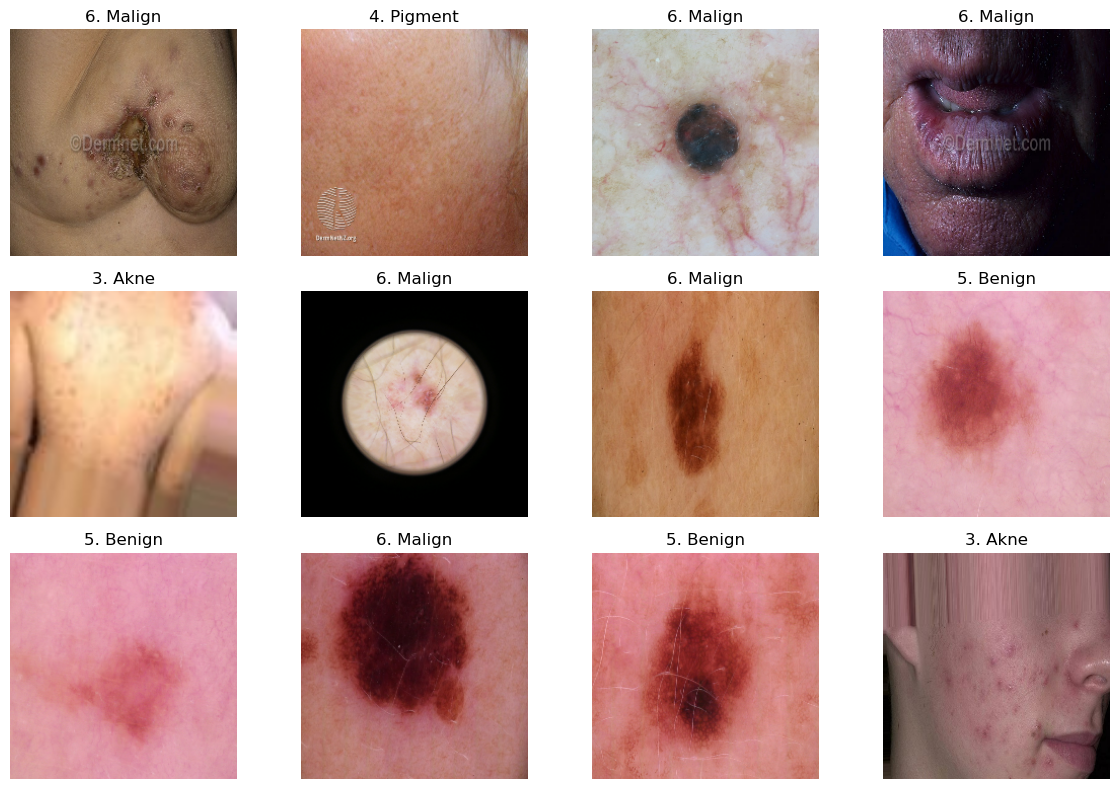

In [7]:
#Comprobamos con algunas imágenes que se han cargado bien
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

Añadimos *DataAugmentation*. Las ventajas son:
- Reduce el sobreajuste (*overfitting*)
- Mejora la capacidad de generalización del modelo
- Permite obtener más variedad de entrenamiento sin aumentar el tamaño del dataset almacenado

In [8]:
from tensorflow.keras import layers, Model, Sequential

data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
], name="data_augmentation")

# Congelamos el backbone
baseline.get_layer("efficientnetv2-b0").trainable = False

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))

x = data_augmentation(inputs)
outputs = baseline(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="efficientnetv2b0_aug"
)

Calculamos los pesos de las clases

In [9]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Obtener las etiquetas del conjunto de entrenamiento
y_train = np.concatenate([
    labels.numpy()
    for images, labels in train_ds
])

# Como las etiquetas están en formato one-hot, convertimos a etiquetas enteras
if y_train.ndim > 1 and y_train.shape[-1] > 1:
    y_train = np.argmax(y_train, axis=1)
else:
    y_train = y_train.reshape(-1)

# Calcular pesos equilibrados
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

# Mostrar resultados
print("Pesos por clase:")
for i, weight in class_weights.items():
    print(f"{class_names[i]}: {weight:.4f}")

Pesos por clase:
1. Enfeksiyonel: 1.1279
2. Ekzama: 1.7013
3. Akne: 2.0939
4. Pigment: 4.3414
5. Benign: 0.4421
6. Malign: 0.6427


Añadimos DataAugmentation y compilamos el modelo

In [10]:

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetV2B0 

base_model = EfficientNetV2B0 (
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)

#Congelamos la red preentrenada
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))


# Extracción de características
x = data_augmentation(inputs)
x = base_model(x, training=False)

# Clasificador
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(inputs, outputs)

model = Model(inputs, outputs, name="efficientnetv2b0_CW_y_DA")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
# Hacemos una pausa para que no pete el kernel de Colab por exceso de memoria, ya que se han cargado varios modelos y datasets
import time; time.sleep(10)

Entrenamiento del modelo

In [12]:
import os
import time
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

RESULTS_DIR = "../src/models/resultados"
os.makedirs(RESULTS_DIR, exist_ok=True)

callbacks = [
    ModelCheckpoint(
        f"{MODELOS_DIR}/efficientnetv2b0_CW_y_DA.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    CSVLogger(
        f"{RESULTS_DIR}/efficientnetv2b0_CW_y_DA_history.csv"
    )
]

inicio = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS, 
    class_weight=class_weights,
    callbacks=callbacks
)

duracion = time.time() - inicio

print(f"Tiempo de entrenamiento: {duracion / 60:.2f} minutos")

Epoch 1/10
1620/1620 [==============================] - ETA: 0s - loss: 1.0280 - accuracy: 0.6191
Epoch 1: val_loss improved from inf to 0.74119, saving model to ../src/models\efficientnetv2b0_CW_y_DA.keras
1620/1620 [==============================] - 291s 172ms/step - loss: 1.0280 - accuracy: 0.6191 - val_loss: 0.7412 - val_accuracy: 0.7143 - lr: 0.0010
Epoch 2/10
1620/1620 [==============================] - ETA: 0s - loss: 0.9141 - accuracy: 0.6616
Epoch 2: val_loss improved from 0.74119 to 0.72677, saving model to ../src/models\efficientnetv2b0_CW_y_DA.keras
1620/1620 [==============================] - 304s 188ms/step - loss: 0.9141 - accuracy: 0.6616 - val_loss: 0.7268 - val_accuracy: 0.7173 - lr: 0.0010
Epoch 3/10
1620/1620 [==============================] - ETA: 0s - loss: 0.8887 - accuracy: 0.6693
Epoch 3: val_loss improved from 0.72677 to 0.70061, saving model to ../src/models\efficientnetv2b0_CW_y_DA.keras
1620/1620 [==============================] - 316s 195ms/step - loss: 0.

Guardamos el modelo entrenado

In [19]:

# Nombre del modelo experimental
MODEL_PATH = Path(MODELOS_DIR) / "efficientnetv2b0_CW_y_DA.keras"

# Guardar el modelo completo
model.save(MODEL_PATH)

print(f"Modelo guardado en: {MODEL_PATH}")
print(f"Tamaño: {MODEL_PATH.stat().st_size / (1024**2):.2f} MB")

Modelo guardado en: ..\src\models\efficientnetv2b0_CW_y_DA.keras
Tamaño: 23.10 MB


Representamos la evolución de la precisión y de la pérdida durante el entrenamiento:
- Si entrenamiento y validación mejoran juntos, el modelo está aprendiendo.
- Si mejora el entrenamiento y empeora la validación hay *overfitting*.
- Si los dos bajan puede haber *underfitting*.
- Si la validación mejora más lento, hay que revisar la calidad y el equilibrio de los datos.

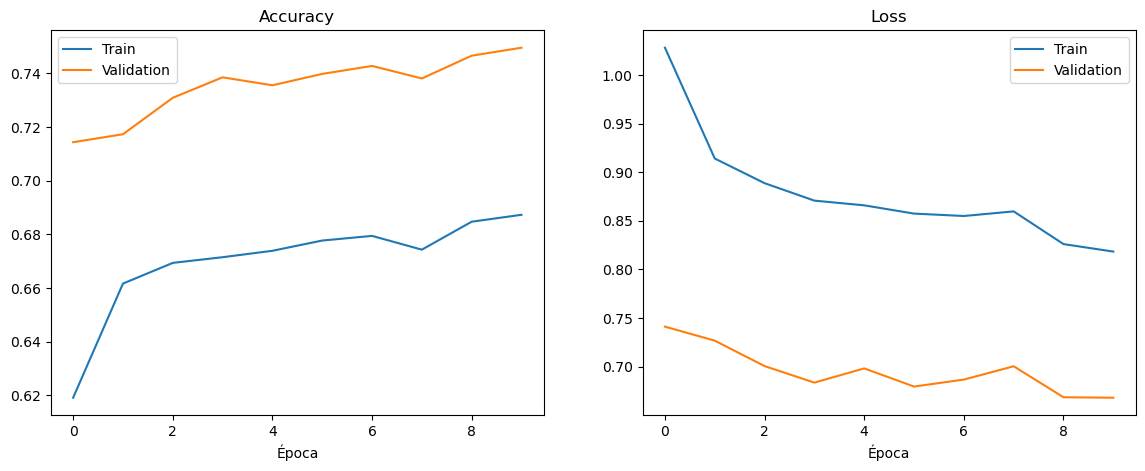

In [20]:
def plot_history(history):
    hist = history.history

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(hist["accuracy"], label="Train")
    axes[0].plot(hist["val_accuracy"], label="Validation")
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Época")
    axes[0].legend()

    axes[1].plot(hist["loss"], label="Train")
    axes[1].plot(hist["val_loss"], label="Validation")
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Época")
    axes[1].legend()

    plt.show()

plot_history(history)

**Evaluación del modelo**

Una precisión global elevada puede ocultar que el modelo clasifica mal algunas enfermedades menos representadas. Para visualizarlo usaremos:
- *Accuracy*: porcentaje global de aciertos.
- *Precision*: proporción de predicciones positivas correctas.
- *Recall*: proporción de imágenes de una clase que consigue detectar.
- *F1-score*: equilibrio entre precision y recall.
- *Macro F1*: media del F1 de todas las clases, dando el mismo peso a cada enfermedad.

In [21]:
import numpy as np
import sklearn
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# Cargar el mejor modelo guardado
best_model = tf.keras.models.load_model(
    f"{MODELOS_DIR}/efficientnetv2b0_CW_y_DA.keras"
)

# Predicciones sobre validación
y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

y_prob = best_model.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Macro F1:", f1_score(y_true, y_pred, average="macro"))
print("Balanced accuracy:", balanced_accuracy_score(y_true, y_pred))

148/148 [==============================] - 11s 69ms/step
                 precision    recall  f1-score   support

1. Enfeksiyonel     0.3891    0.6730    0.4931       159
      2. Ekzama     0.2990    0.3919    0.3392        74
        3. Akne     0.8043    0.8457    0.8245       175
     4. Pigment     0.6897    0.5405    0.6061       111
      5. Benign     0.8464    0.8531    0.8497      1014
      6. Malign     0.8061    0.6768    0.7358       823

       accuracy                         0.7496      2356
      macro avg     0.6391    0.6635    0.6414      2356
   weighted avg     0.7737    0.7496    0.7565      2356

Accuracy: 0.7495755517826825
Macro F1: 0.6413910828248713
Balanced accuracy: 0.6634920192954712


Matriz de confusión

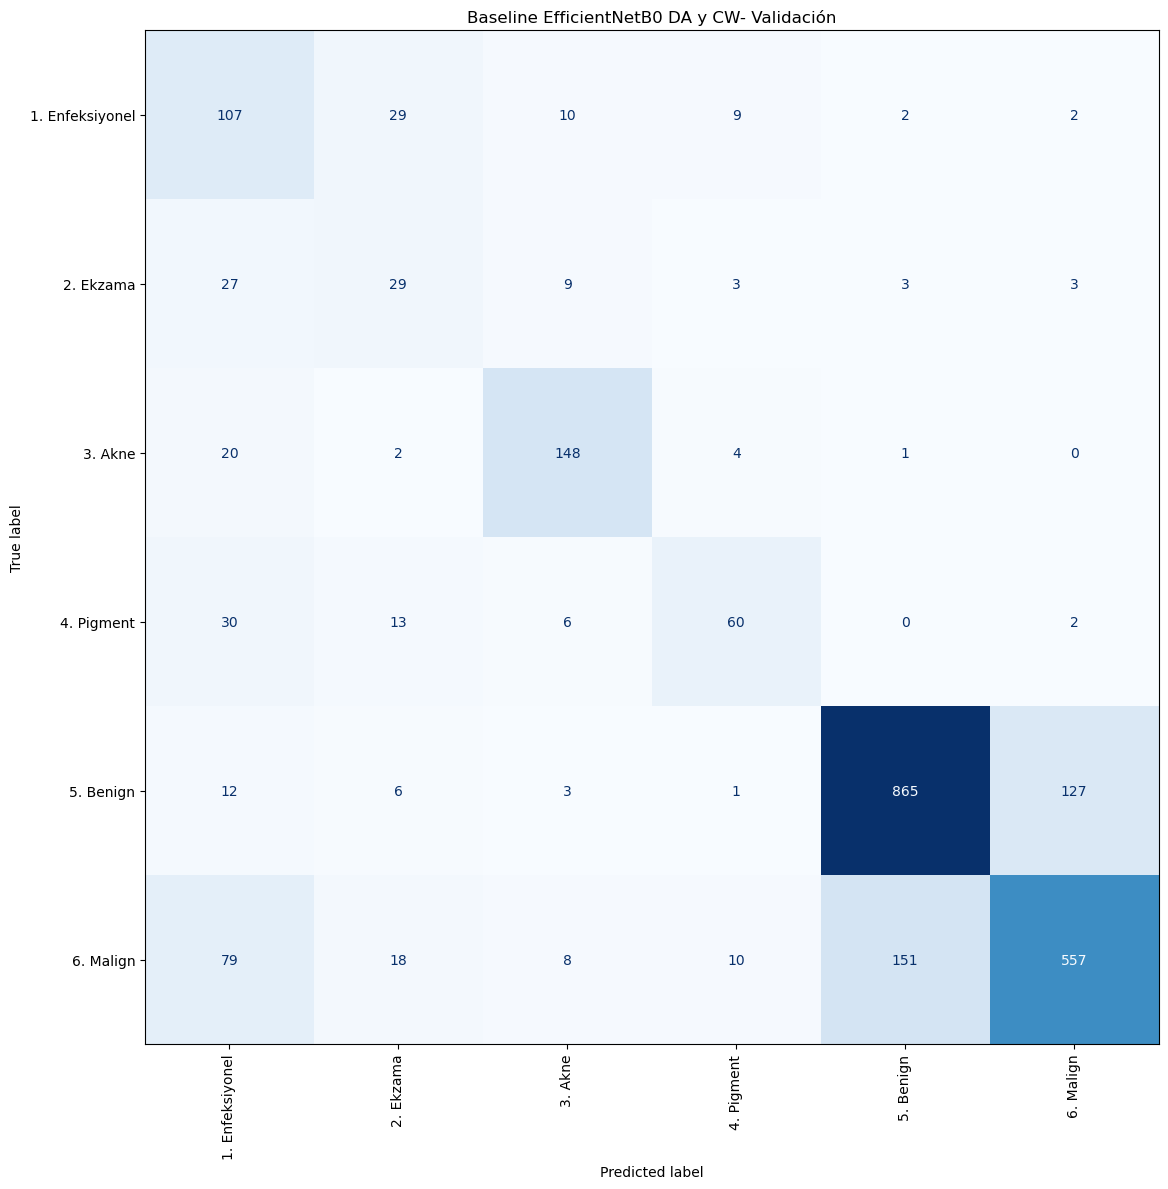

In [16]:

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(12, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("Baseline EfficientNetB0 DA y CW- Validación")
plt.tight_layout()
plt.show()

Incorporamos datos al fichero de resultados

In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score
resultado_baseline = {
    "modelo": "EfficientNetv2B0",
    "archivo": "efficientnetv2b0_CW_y_DA.keras",
    "tipo": "Transfer learning - capas congeladas",
    "resolucion": "224x224",
    "batch_size": BATCH_SIZE,
    "learning_rate": 0.001,
    "epochs": len(history.history["loss"]),
    "tiempo_minutos": round(duracion / 60, 2),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_true, y_pred)
    )
}

resultados = pd.DataFrame([resultado_baseline])

resultados.to_csv(
    f"{RESULTS_DIR}/comparativa_modelos.csv",
    index=False
)